# Unit 8: gradient descent and the cost function

The module's notebook is kept as it was. It prints all 100 iterations. Everything under **My changes** is mine.

The data is five points on the line **y = 2x + 3**, so the right answer is known: slope m = 2, intercept
b = 3, cost 0. That makes it easy to see whether a setting actually gets there.

*The comments at the end of the module's own code lines are mine, added to explain what each line does. The module's original comments are unchanged.*

## Calculating cost with gradient descent and learning rate
- Change the iteration and learning rate vaules and see the impact on cost. 
- Low iteration values with high learning rate (i.e. big steps) may lead to miss the global minimum
- Goal is to reach minimum cost with minimum iteration

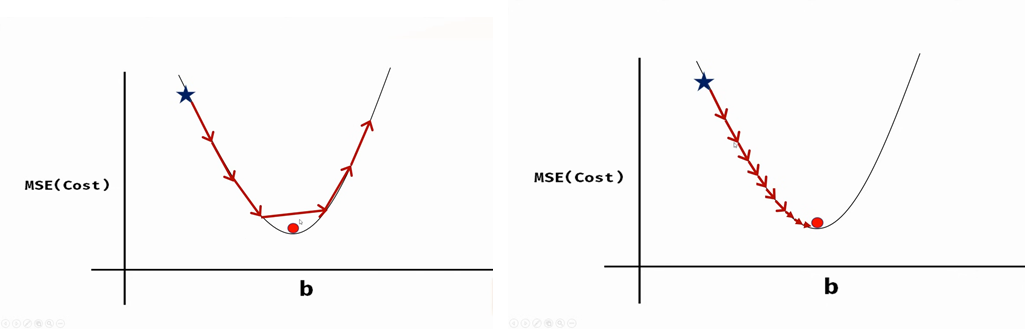

In [1]:
# code credit:codebasics https://codebasics.io/coming-soon

import numpy as np                                  # arrays and maths

def gradient_descent(x,y):                          # find the best slope and intercept by small steps downhill
    m_curr = b_curr = 0                             # start with slope 0 and intercept 0
    iterations = 100       #change value
    n = len(x)                                      # number of data points
    learning_rate = 0.08   #change value

    for i in range(iterations):                     # one step per iteration
        y_predicted = m_curr * x + b_curr           # predictions from the current line
        cost = (1/n) * sum([val**2 for val in (y-y_predicted)])  # cost = mean squared error
        md = -(2/n)*sum(x*(y-y_predicted))          # gradient of the cost with respect to the slope
        bd = -(2/n)*sum(y-y_predicted)              # gradient of the cost with respect to the intercept
        m_curr = m_curr - learning_rate * md        # step the slope downhill
        b_curr = b_curr - learning_rate * bd        # step the intercept downhill
        print ("m {}, b {}, cost {} iteration {}".format(m_curr,b_curr,cost, i))  # show progress each step

x = np.array([1,2,3,4,5])                           # inputs
y = np.array([5,7,9,11,13])                         # outputs, exactly y = 2x + 3

gradient_descent(x,y)                               # run it

m 4.96, b 1.44, cost 89.0 iteration 0
m 0.4991999999999983, b 0.26879999999999993, cost 71.10560000000002 iteration 1
m 4.451584000000002, b 1.426176000000001, cost 56.8297702400001 iteration 2
m 0.892231679999997, b 0.5012275199999995, cost 45.43965675929613 iteration 3
m 4.041314713600002, b 1.432759910400001, cost 36.35088701894832 iteration 4
m 1.2008760606719973, b 0.7036872622079998, cost 29.097483330142282 iteration 5
m 3.7095643080294423, b 1.4546767911321612, cost 23.307872849944438 iteration 6
m 1.4424862661541864, b 0.881337636696883, cost 18.685758762535738 iteration 7
m 3.4406683721083144, b 1.4879302070713722, cost 14.994867596913156 iteration 8
m 1.6308855378034224, b 1.0383405553279617, cost 12.046787238456794 iteration 9
m 3.2221235247119777, b 1.5293810083298451, cost 9.691269350698109 iteration 10
m 1.7770832372205707, b 1.1780607551353204, cost 7.8084968312098315 iteration 11
m 3.0439475772474127, b 1.5765710804477953, cost 6.302918117062937 iteration 12
m 1.8898457

## My changes

The task was to change the number of iterations and the learning rate and watch the cost. Rather than edit
and rerun one cell by hand, I turned the module's loop into a function that returns the cost at every step,
so I could try lots of settings side by side. The maths inside the loop is the same as the module's.

In [2]:
import numpy as np                                   # numpy: arrays and maths
import matplotlib.pyplot as plt                      # plotting

def gd(x, y, learning_rate, iterations):             # the module's gradient descent, returning the cost at every step
    m = b = 0.0                                      # start with slope 0 and intercept 0, like the module
    n = len(x)                                       # number of data points
    costs = []                                       # cost recorded at each iteration
    for _ in range(iterations):                      # one step downhill per iteration
        y_pred = m * x + b                           # current line's predictions
        costs.append((1 / n) * np.sum((y - y_pred) ** 2))   # cost = mean squared error of those predictions
        md_ = -(2 / n) * np.sum(x * (y - y_pred))    # slope of the cost with respect to m (the gradient for m)
        bd = -(2 / n) * np.sum(y - y_pred)           # slope of the cost with respect to b (the gradient for b)
        m, b = m - learning_rate * md_, b - learning_rate * bd   # step both downhill, scaled by the learning rate
    return m, b, np.array(costs)                     # final line and the full cost history

x = np.array([1, 2, 3, 4, 5])                        # the module's x values
y = np.array([5, 7, 9, 11, 13])                      # the module's y values: exactly y = 2x + 3

print(f"{'learning rate':>13} | {'iterations':>10} | {'m (want 2)':>10} | {'b (want 3)':>10} | {'final cost':>12}")  # table header
for lr in [0.001, 0.01, 0.05, 0.08, 0.09, 0.1]:      # learning rates, including the module's default of 0.08
    for its in [10, 100, 1000, 10000]:               # numbers of iterations
        with np.errstate(over="ignore", invalid="ignore"):   # hide numpy's overflow warnings when a run blows up
            m, b, c = gd(x, y, lr, its)              # run gradient descent with this combination
        print(f"{lr:>13} | {its:>10} | {m:>10.4g} | {b:>10.4g} | {c[-1]:>12.3g}")   # where it ended up
    print("-" * 66)                                  # separator between learning rates

learning rate | iterations | m (want 2) | b (want 3) |   final cost
        0.001 |         10 |     0.5578 |     0.1628 |         58.2
        0.001 |        100 |      2.369 |     0.7374 |         1.65
        0.001 |       1000 |      2.449 |       1.38 |        0.478
        0.001 |      10000 |      2.021 |      2.923 |      0.00109
------------------------------------------------------------------
         0.01 |         10 |      2.432 |      0.755 |         1.57
         0.01 |        100 |      2.448 |      1.381 |         0.48
         0.01 |       1000 |      2.021 |      2.923 |      0.00108
         0.01 |      10000 |          2 |          3 |     1.04e-27
------------------------------------------------------------------
         0.05 |         10 |      2.531 |      1.084 |        0.691
         0.05 |        100 |      2.114 |      2.587 |       0.0321
         0.05 |       1000 |          2 |          3 |     1.51e-15
         0.05 |      10000 |          2 |         

### Cost over time for different learning rates

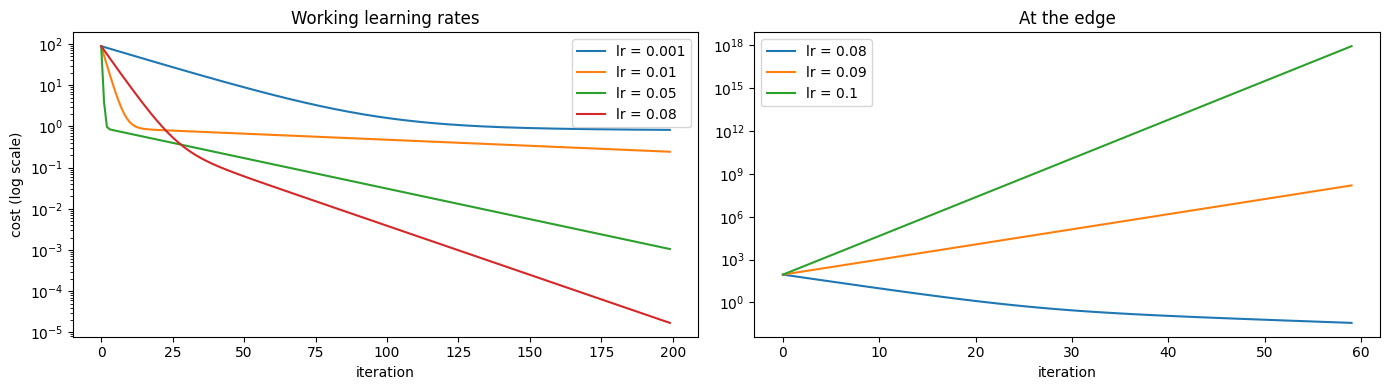

In [3]:
fig, axes = plt.subplots(1, 2, figsize=(14, 4))      # two plots side by side
for lr in [0.001, 0.01, 0.05, 0.08]:                 # rates that work
    _, _, c = gd(x, y, lr, 200)                      # 200 iterations each
    axes[0].plot(c, label=f"lr = {lr}")              # cost curve
axes[0].set_yscale("log"); axes[0].set_xlabel("iteration"); axes[0].set_ylabel("cost (log scale)")   # log scale shows the fall clearly
axes[0].set_title("Working learning rates"); axes[0].legend()  # title and legend

for lr in [0.08, 0.09, 0.1]:                         # the module's default and two rates just above it
    with np.errstate(over="ignore", invalid="ignore"):   # these may overflow
        _, _, c = gd(x, y, lr, 60)                   # 60 iterations is enough to see the difference
    axes[1].plot(c, label=f"lr = {lr}")              # cost curve
axes[1].set_yscale("log"); axes[1].set_xlabel("iteration"); axes[1].set_title("At the edge")  # log scale, label, title
axes[1].legend(); plt.tight_layout(); plt.show()     # draw

### How many iterations to get close?

In [4]:
# Iterations needed before the cost first drops below 0.0001
for lr in [0.001, 0.01, 0.05, 0.08, 0.09]:           # each learning rate
    with np.errstate(over="ignore", invalid="ignore"):   # 0.09 overflows, so hide the warnings
        _, _, c = gd(x, y, lr, 100000)               # run for a long time
    hit = np.argmax(c < 1e-4) if np.any(c < 1e-4) else None   # first iteration below the target, if it ever gets there
    print(f"lr {lr:<6} -> {'never' if hit is None else f'{hit:,} iterations'}")  # iterations needed, or never

# The largest safe learning rate for this data depends on how steep the cost surface is.
# For a squared-error cost, gradient descent stays stable while lr < 2 / (the largest curvature of the surface).
# The curvature is measured by the Hessian matrix, and its largest eigenvalue is the steepest direction.
X = np.c_[x, np.ones_like(x)]                        # inputs with a column of 1s for the intercept
H = (2 / len(x)) * X.T @ X                           # Hessian of the mean squared error for this data
print(f"\nLargest stable learning rate for this data: {2 / np.linalg.eigvalsh(H).max():.4f}")   # the limit

lr 0.001  -> 13,527 iterations
lr 0.01   -> 1,351 iterations
lr 0.05   -> 269 iterations
lr 0.08   -> 167 iterations
lr 0.09   -> never

Largest stable learning rate for this data: 0.0845


## What I took from it


- **The learning rate is the size of each step downhill.** Too small and it crawls. At 0.001 it needed 13,527
  iterations to get close. At 0.08 it needed 167. Same answer, about 80 times fewer steps.
- **Too big and it falls off the hill.** At 0.09 the cost went *up*, from 790 after 10 steps to a number with
  over 100 digits after 1,000, and then the maths broke (`nan`). Each step overshot the bottom and landed
  higher up the other side, a bit further every time.
- **The module's default sits right on the edge.** For this data the largest safe learning rate works out at
  0.0845, and the module uses 0.08. It works, but only just. You can see it in the table: after 10 steps,
  0.08 has a *higher* cost (12) than 0.05 (0.69), because it's zig-zagging across the valley before it settles.
  A 10% change to 0.09 is the difference between converging and exploding.
- **Iterations and learning rate trade against each other.** 0.001 for 10,000 iterations lands in the same place
  as 0.01 for 1,000. More iterations only help if the step size is safe in the first place.
- **The safe limit depends on the data, not just the code.** That limit comes from how steep the cost surface
  is, which comes from the size of the x values. Feed the same code bigger numbers and 0.08 would blow up.
  That's why features are usually scaled before training, and why the module's note says to aim for the
  minimum cost in the fewest iterations rather than just cranking the rate up.